In [1]:
import ensaio
import xarray as xr
import numpy as np
import scipy as sp
import harmonica as hm
import verde as vd
import numba
import choclo.constants
import matplotlib.pyplot as plt
import matplotlib.patches
import pathlib
import matplotlib.colors as mcolors
from matplotlib.ticker import LogLocator, NullFormatter
from matplotlib.lines import Line2D


import skimage.exposure
import warnings
import rich.progress

import sys
sys.path.append("..")
import micromag as mg
import multipoles as mt

In [2]:
figure_dir = pathlib.Path("../../paper/figures")

## Read data using ensaio

In [3]:
path_data = ensaio.fetch_morroco_speleothem_qdm(file_format="matlab", version=1)
data = mg.load_qdm(path_data)

height_difference = 5
data_up = (
    hm.upward_continuation(data.bz, height_difference)
    .assign_attrs(data.bz.attrs)
    .to_dataset(name="bz")
    .assign_coords(x=data.x, y=data.y)
    .assign_coords(z=data.z + height_difference)
)

data_up = data_up.assign(mg.data_gradients(data_up.bz))

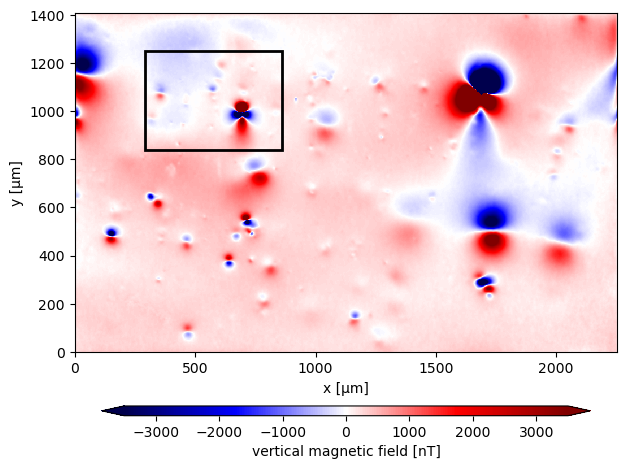

In [4]:
fig, axes = plt.subplots(1, 1, figsize=(7, 7))
cbar_kwargs = dict(orientation="horizontal", aspect=50, pad=0.1, shrink=0.9)
scale = 3500
data_up.bz.plot.pcolormesh(vmin=-scale, vmax=scale, cmap='seismic',  cbar_kwargs=cbar_kwargs)
axes.set_aspect("equal")


# define window for the selected anomaly
# window = [1500, 1850, 800, 1300] # single anomaly
# window = [1200, 1775, 950, 1200]
window = [290, 860, 840, 1250]
# window = [1200, 1800, 800, 1300]

rect = matplotlib.patches.Rectangle(
    xy=[window[0], window[2]],
    width=window[1] - window[0],
    height=window[3] - window[2],
    edgecolor="k",
    fill=False,
    linewidth=2,
)
axes.add_patch(rect)

# axes.text(window[0]-120, window[2]-60, 'selected source')

## Select anomaly

In [5]:
# data = data.sel(x=slice(*window[:2]), y=slice(*window[2:]))
# data_up = data_up.sel(x=slice(*window[:2]), y=slice(*window[2:]))

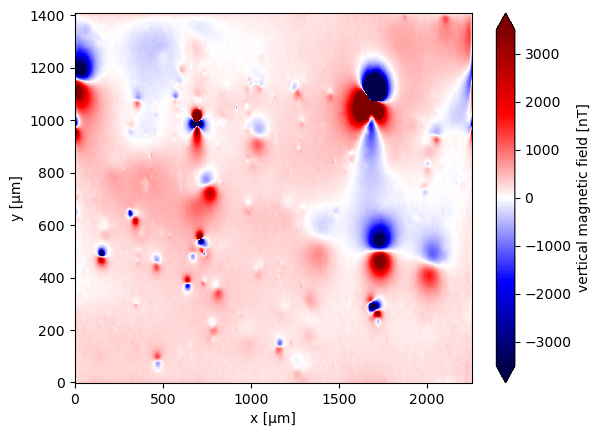

In [6]:
data_up.bz.plot.pcolormesh(cmap="seismic", vmax=scale, vmin=-scale)

In [7]:
stretched = skimage.exposure.rescale_intensity(
    data_up.tga, 
    in_range=tuple(np.percentile(data_up.tga, (1, 99))),
)
data_up = data_up.assign(tga_stretched=xr.DataArray(stretched, coords=data_up.coords))

In [8]:
windows = mg.detect_anomalies(
    data_up.tga_stretched, 
    size_range=[40, 200],
    size_increment=1.0,
    threshold=0.02,
    overlap=0.0,
    exclude_border=30,
    nsizes=10,
)


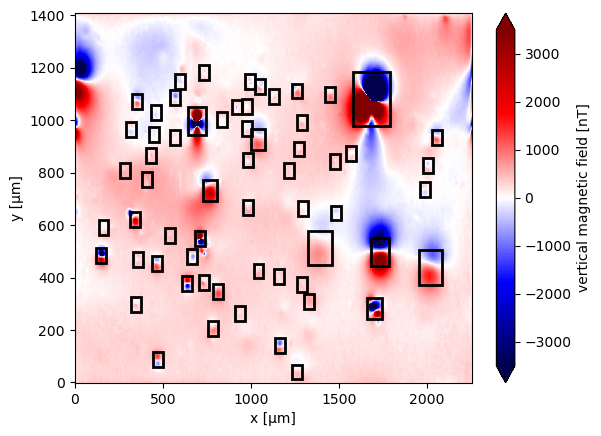

In [9]:
ax = plt.subplot(111)
data_up.bz.plot.pcolormesh(ax=ax, cmap="seismic", vmax=scale, vmin=-scale)
for window in windows:
    rect = matplotlib.patches.Rectangle(
        xy=[window[0], window[2]],
        width=window[1] - window[0],
        height=window[3] - window[2],
        edgecolor="k",
        fill=False,
        linewidth=2,
    )
    ax.add_patch(rect) 

## Non-linear dipole fitting

In [10]:
def goal_function_dipole(parameter, obs_data, coordinates, amplitude, x_0, y_0, z_0):
    bz = mg.dipole_bz(coordinates, 
                      ([parameter[0]*x_0], [parameter[1]*y_0], [parameter[2]*z_0]),
                     np.array([parameter[3], parameter[4], parameter[5]])*amplitude
                     )
    
    Res = np.linalg.norm(obs_data-bz.ravel())
    return(Res)

whole_table = vd.grid_to_table(data_up)
coordinates_whole = (whole_table.x, whole_table.y, whole_table.z)

In [11]:
data_copy = data.copy(deep=True)
data_up_copy = data_up.copy(deep=True)
data_up = data_up.assign(dipole_nonlinear=(['y','x'], np.zeros_like(data_up.bz)))


estimated_dipole_moments_dip = []
positions_dipole = []
base_levels_dipole = []

for window in rich.progress.track(np.array(windows), total = len(np.array(windows))):

    anomaly = data_up_copy.sel(x=slice(*window[:2]), y=slice(*window[2:]))

    table = vd.grid_to_table(anomaly)
    coordinates = (anomaly.x, anomaly.y, anomaly.z)
    
    position, base_level = mg.euler_deconvolution(
            anomaly.bz, 
            anomaly.x_deriv, 
            anomaly.y_deriv, 
            anomaly.z_deriv,
        )
    
    data_minus_background = anomaly.bz.values - base_level
    anomaly = anomaly.assign(data_minus_background=(['y','x'], data_minus_background))
    anomaly.data_minus_background.attrs = {"long_name": "dipole-model", "units": "nT"}

    moment, covariance, r2, SNR = mg.dipole_moment_inversion(
        anomaly.data_minus_background, position,
    )
    
    anomaly_table=vd.grid_to_table(anomaly)
    amplitude = np.linalg.norm(moment)
    
    
    ## SCIPY MINIMIZATION DIPOLE
    args_dip=(anomaly_table.bz.ravel(), 
         ( anomaly_table.x.values,
           anomaly_table.y.values, 
           anomaly_table.z.values.ravel()),
           amplitude, position[0], position[1], position[2])
    
    minimization=sp.optimize.minimize(goal_function_dipole, (1, 1, 1,
                                                      moment[0]/amplitude,
                                                      moment[1]/amplitude,
                                                      moment[2]/amplitude),
                                      args=args_dip,
                                      method='Nelder-Mead', options=dict(maxiter=1000))
    
    if minimization.success:
        
        moment = np.array([minimization['x'][3], minimization['x'][4], minimization['x'][5]])*amplitude
        position = np.array([minimization['x'][0]*position[0], 
                             minimization['x'][1]*position[1],
                             minimization['x'][2]*position[2]])
    estimated_dipole_moments_dip.append(moment)
    positions_dipole.append(position)
    base_levels_dipole.append(base_level)

    pred = mg.dipole_bz(coordinates_whole, 
              position,
              moment
             )
    # data_up = data_up.assign(dipole_nonlinear=(['y','x'], data_up.dipole_nonlinear.values + np.reshape(pred, np.shape(data_up.bz))))

    shape = np.shape(data_up.bz)
    data_up.dipole_nonlinear.values += pred.reshape(shape)
    
    discard = mg.dipole_bz(coordinates_whole, position, moment)
    data_copy.bz.values -= discard.reshape(shape)
    data_up_copy = (
                hm.upward_continuation(data_copy.bz, height_difference)
                .assign_attrs(data_copy.bz.attrs)
                .to_dataset(name="bz")
                .assign_coords(x=data_copy.x, y=data_copy.y)
                .assign_coords(z=data_copy.z + height_difference)
                   )
    data_up_copy = data_up_copy.assign(mg.data_gradients(data_up_copy.bz))



Output()

In [12]:
# data_anomaly = data_anomaly.assign(dipole_nonlinear=(['y','x'], pred))
data_up = data_up.assign(residual_dipole=(['y','x'], data_up.bz.values - data_up.dipole_nonlinear.values))

data_up.dipole_nonlinear.attrs = {"long_name": "dipole-model", "units": "nT"}
data_up.residual_dipole.attrs = {"long_name": "residual-dipole-model", "units": "nT"}


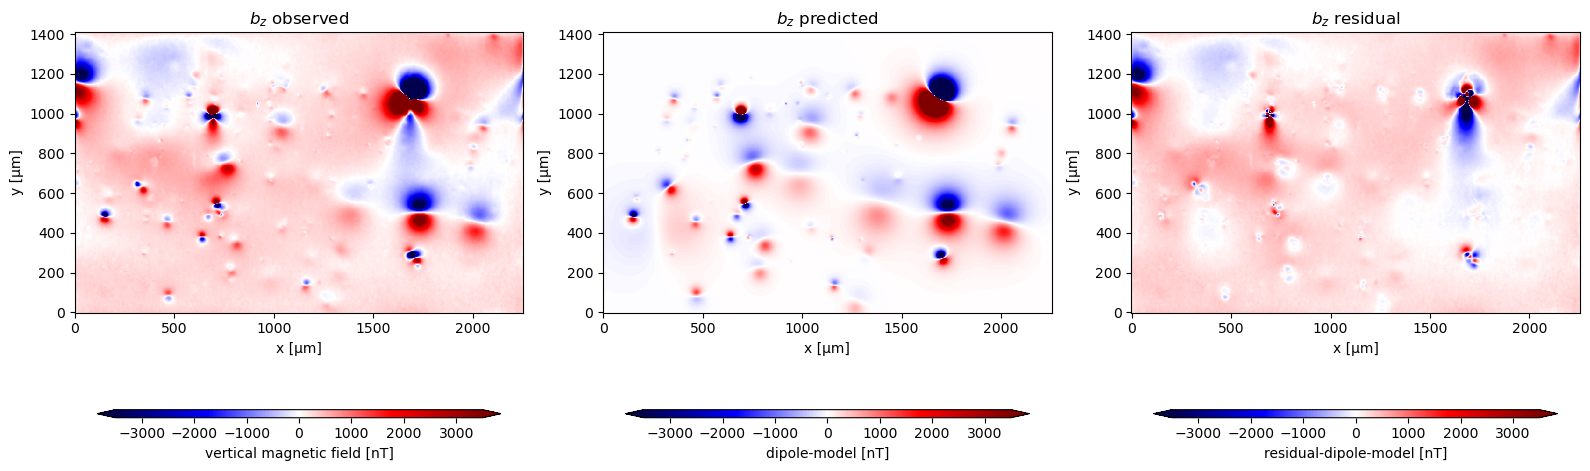

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 10))
cbar_kwargs = dict(orientation="horizontal", aspect=50, pad=0.1, shrink=0.9)
vmax =  3500
vmin = -3500 #data['bz_total'].values.min()
for field, ax in zip(["bz", "dipole_nonlinear", "residual_dipole"], axes.ravel()):

    data_up[field].plot.pcolormesh(ax=ax, cmap="seismic", cbar_kwargs=cbar_kwargs, vmax=vmax, vmin=vmin)
for ax, title in zip(axes.ravel(), [r'$b_z$ observed', r'$b_z$ predicted', r'$b_z$ residual']):
    ax.set_aspect("equal")
    ax.set_title(title)

plt.tight_layout()

## Spherical Harmonic fitting

In [14]:
MAX_DEGREE=5
DAMPING=1.0e0

In [15]:
data_copy = data.copy(deep=True)
data_up_copy = data_up.copy(deep=True)
data_up = data_up.assign(spherical_harmonic=(['y','x'], np.zeros_like(data_up.bz)))

estimated_dipole_moments_SH = []
positions_SH = []
positions_dipole = []
base_levels_SH = []

r2_dipolar_estatimates = np.zeros(len(windows))
r2_multipolar_estatimates = np.zeros(len(windows))
SH_was_used = np.zeros(len(windows)) ## bool point if SH was used

total_data_table = vd.grid_to_table(data_up)
coordinates = (total_data_table.x, total_data_table.y, total_data_table.z)

for i, window in enumerate(rich.progress.track(np.array(windows), total=len(windows))):

    anomaly = data_up_copy.sel(x=slice(*window[:2]), y=slice(*window[2:]))
    
    position, base_level = mg.euler_deconvolution(
            anomaly.bz, 
            anomaly.x_deriv, 
            anomaly.y_deriv, 
            anomaly.z_deriv,
        )
    
    data_minus_background = anomaly.bz.values - base_level
    anomaly = anomaly.assign(data_minus_background=(['y','x'], data_minus_background))
    anomaly.data_minus_background.attrs = {"long_name": "dipole-model", "units": "nT"}

    anomaly_table = vd.grid_to_table(anomaly)
    local_coordinates = (anomaly_table.x, anomaly_table.y, anomaly_table.z)

#################################################################
    moment, covariance, r2, SNR = mg.dipole_moment_inversion(
        anomaly.data_minus_background, position,
    )
    
    anomaly_table = vd.grid_to_table(anomaly)
    amplitude = np.linalg.norm(moment)
    
    ## SCIPY MINIMIZATION DIPOLE
    args_dip = (anomaly_table.bz.ravel(), 
         ( anomaly_table.x.values,
           anomaly_table.y.values, 
           anomaly_table.z.values.ravel()),
           amplitude, position[0], position[1], position[2])
    
    minimization = sp.optimize.minimize(goal_function_dipole, (1, 1, 1,
                                                      moment[0]/amplitude,
                                                      moment[1]/amplitude,
                                                      moment[2]/amplitude),
                                      args=args_dip,
                                      method='Nelder-Mead', options=dict(maxiter=1000))
    multi = False
    moment_dipole = moment.copy()
    position_dipole = position.copy()
    r2_dipole = r2     

    if minimization.success:
        moment = np.array([minimization['x'][3], minimization['x'][4], minimization['x'][5]]) * amplitude
        position = np.array([minimization['x'][0]*position[0], 
                             minimization['x'][1]*position[1],
                             minimization['x'][2]*position[2]])
        
        xxx, yyy = np.meshgrid(anomaly.x.values, anomaly.y.values)
        zzz = anomaly.z.values.ravel()
        local_coordinates = [xxx.ravel(), yyy.ravel(), zzz]
        pred = mg.dipole_bz(local_coordinates, position, moment)
        
        residuals = data_minus_background.ravel() - pred.ravel()
        residuals_sum_sq = np.sum(residuals**2)
        r2 = 1 - residuals_sum_sq / np.linalg.norm(data_minus_background.ravel() - np.mean(data_minus_background.ravel())) ** 2
        
        moment_dipole = moment.copy()
        position_dipole = position.copy()
        r2_dipole = r2     

        r2_dipolar_estatimates[i] = r2_dipole
        r2_multipolar_estatimates[i] = r2_dipole  
        
        if r2_dipole <= 0.95:
            multi = True
            r2_bubble = r2_dipole
            #################################################################    
            sph = mt.SphericalHarmonicsBz(position, damping=DAMPING, min_degree=1, max_degree=MAX_DEGREE).fit(local_coordinates, anomaly_table.data_minus_background)
            sph.update_location(local_coordinates, anomaly_table.data_minus_background, update_only_z=False)
            pred_sph = sph.predict(local_coordinates, min_degree=1, max_degree=MAX_DEGREE)
            residuals = data_minus_background.ravel() - pred_sph.ravel()
            residuals_sum_sq = np.sum(residuals**2)
            r2_sh = 1 - residuals_sum_sq / np.linalg.norm(data_minus_background.ravel() - np.mean(data_minus_background.ravel())) ** 2
            
            if r2_sh >= r2_bubble:
                moment = sph.magnetic_moment_
                position = sph.location
                pred = pred_sph
                r2 = r2_sh
                r2_multipolar_estatimates[i] = r2_sh  
                SH_was_used[i] = 1 
            else:
                multi = False 

    #### Avoid unrealistic deep solutions      
    if (position[2] < -300) or (position[2] > 5):
        moment = moment_dipole
        position = position_dipole
        r2 = r2_dipole
        multi = False
        SH_was_used[i] = 0
        r2_multipolar_estatimates[i] = r2_dipole
            
    estimated_dipole_moments_SH.append(moment)
    positions_SH.append(position)
    positions_dipole.append(position_dipole)
    base_levels_SH.append(base_level)
    
    if not minimization.success:
        r2_dipolar_estatimates[i] = r2_dipole
        r2_multipolar_estatimates[i] = r2_dipole

    ######### Fill the predicted data and discard anomalies ########
    if r2 < 0.95:
        discard = np.zeros_like(data_copy.bz.values)
    
    if multi:
        discard = sph.predict(coordinates, min_degree=1, max_degree=MAX_DEGREE)
    else:
        discard = mg.dipole_bz(coordinates, position, moment)
    
    max_discard = np.max(np.abs(discard))
    max_field = np.max(np.abs(data_copy.bz.values))
    
    if max_discard > 2 * max_field:
        print(f"Rejecting subtraction: discard too large ({max_discard:.2e} > {2*max_field:.2e})")
        discard = np.zeros_like(data_copy.bz.values)

    shape = np.shape(data_up.bz)
    data_up.spherical_harmonic.values += discard.reshape(shape)
    data_copy.bz.values -= discard.reshape(shape)
    
    if np.isnan(data_copy.bz.values).any():
        print(f"NaN found after subtraction, replacing with zero")
        data_copy["bz"] = data_copy.bz.fillna(0)

    data_up_copy = (
                hm.upward_continuation(data_copy.bz, height_difference)
                .assign_attrs(data_copy.bz.attrs)
                .to_dataset(name="bz")
                .assign_coords(x=data_copy.x, y=data_copy.y)
                .assign_coords(z=data_copy.z + height_difference)
                   )
    data_up_copy = data_up_copy.assign(mg.data_gradients(data_up_copy.bz))

Output()

In [16]:
data_up = data_up.assign(residual_spherical=(['y','x'], data_up.bz.values - data_up.spherical_harmonic.values))

data_up.spherical_harmonic.attrs = {"long_name": "spherical-model", "units": "nT"}
data_up.residual_spherical.attrs = {"long_name": "residual-spherical", "units": "nT"}


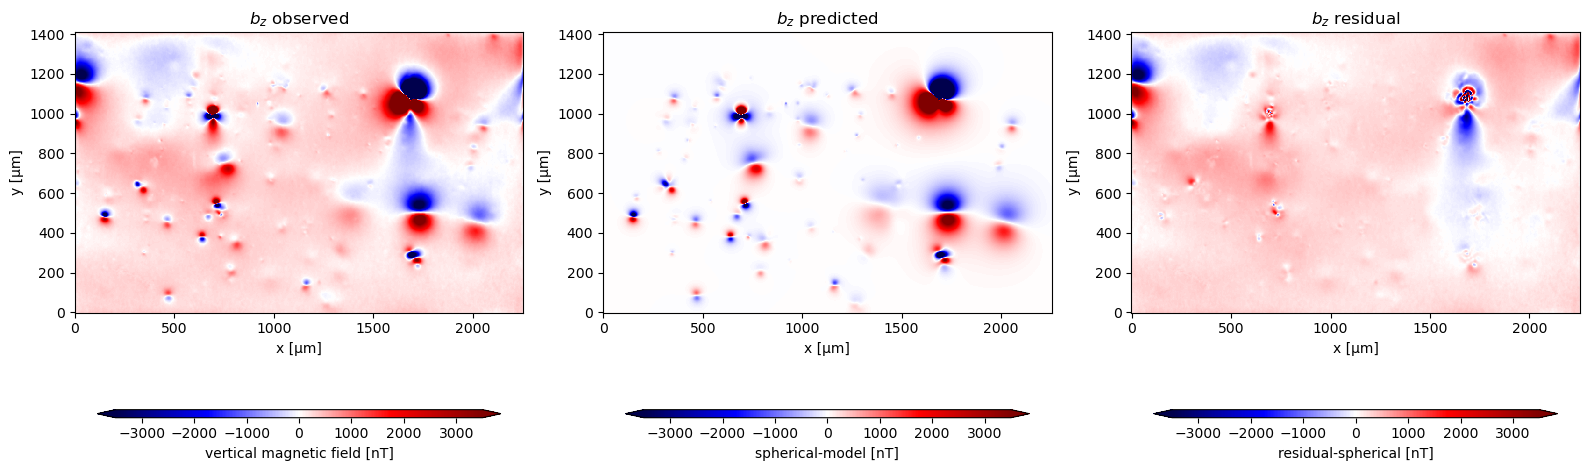

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 10))
cbar_kwargs = dict(orientation="horizontal", aspect=50, pad=0.1, shrink=0.9)
vmax =  3500
vmin = -3500 #data['bz_total'].values.min()
for field, ax in zip(["bz", "spherical_harmonic", "residual_spherical"], axes.ravel()):

    data_up[field].plot.pcolormesh(ax=ax, cmap="seismic", cbar_kwargs=cbar_kwargs, vmax=vmax, vmin=vmin)
for ax, title in zip(axes.ravel(), [r'$b_z$ observed', r'$b_z$ predicted', r'$b_z$ residual']):
    ax.set_aspect("equal")
    ax.set_title(title)

plt.tight_layout()

## Figure

In [18]:
zooms = [
windows[0], 
windows[22],#32
windows[4]#2
]

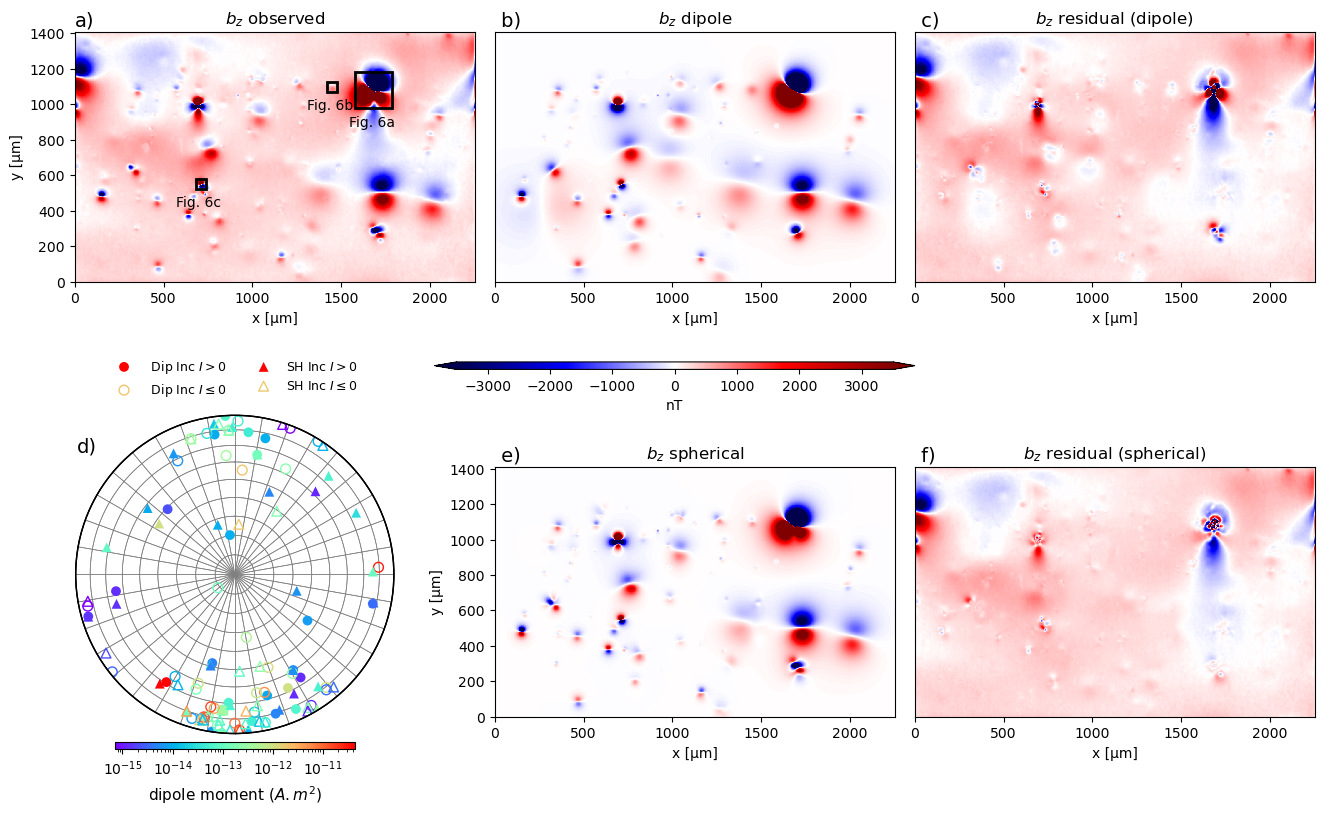

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))#, sharey='row', sharex='col')

vmax = 3500
vmin = -3500

# ===== FIRST ROW =====
# Observed data (reference for colorbar)
im = data_up["bz"].plot.pcolormesh(
    ax=axes[0, 0],
    cmap="seismic",
    vmin=vmin,
    vmax=vmax,
    add_colorbar=False
)

letters = ["a", "b", "c"]
for letter, window in zip(letters, zooms):
    rect = matplotlib.patches.Rectangle(
        xy=[window[0], window[2]],
        width=window[1] - window[0],
        height=window[3] - window[2],
        edgecolor="k",
        fill=False,
        linewidth=2,
    )
    axes[0,0].add_patch(rect)  

    # axes[0,0].text((window[0]+window[1])/2-30, window[3]+10, f'Fig. 5{letter}')
    axes[0,0].text((window[0]+window[1])/2-140, window[2]-100, f'Fig. 6{letter}')

# Dipole prediction
data_up["dipole_nonlinear"].plot.pcolormesh(
    ax=axes[0, 1],
    cmap="seismic",
    vmin=vmin,
    vmax=vmax,
    add_colorbar=False
)

# Dipole residual
data_up["residual_dipole"].plot.pcolormesh(
    ax=axes[0, 2],
    cmap="seismic",
    vmin=vmin,
    vmax=vmax,
    add_colorbar=False
)

# ===== SECOND ROW =====
# Empty axis (reserved for stereonet later)
axes[1, 0].axis("off")

# Spherical harmonic prediction
data_up["spherical_harmonic"].plot.pcolormesh(
    ax=axes[1, 1],
    cmap="seismic",
    vmin=vmin,
    vmax=vmax,
    add_colorbar=False
)

# Spherical residual
data_up["residual_spherical"].plot.pcolormesh(
    ax=axes[1, 2],
    cmap="seismic",
    vmin=vmin,
    vmax=vmax,
    add_colorbar=False
)

# ===== TITLES AND ASPECT =====
titles = [
    r"$b_z$ observed", r"$b_z$ dipole", r"$b_z$ residual (dipole)",
    "", r"$b_z$ spherical", r"$b_z$ residual (spherical)"
]

for ax, title in zip(axes.ravel(), titles):
    ax.set_title(title)
    ax.set_aspect("equal")


for ax in [axes[0, 1], axes[0, 2], axes[1, 2]]:
    ax.set_ylabel("")                 # remove y-axis label
    ax.set_yticklabels([])            # remove tick labels
    ax.tick_params(axis='y', which='both', length=0)  # remove tick marks


cbar_ax = fig.add_axes([0.35, 0.5, 0.3, 0.0075])#[0.11, 0.15, 0.23, 0.015])

cbar = fig.colorbar(
    im,
    cax=cbar_ax,
    extend='both',
    orientation="horizontal"
)

cbar.set_label("nT")


## Add stereogram
ax = fig.add_axes([0.05, 0.12, 0.35, 0.35])

projection_SH = mg.StereographicProjection(estimated_dipole_moments_SH)
projection_dip = mg.StereographicProjection(estimated_dipole_moments_dip)

cmap = "rainbow"
cmap_norm = matplotlib.colors.LogNorm #Normalize
kwargs = dict(
    s=50, cmap=cmap, cmap_norm=cmap_norm
)   

# Plota a projeção estereográfica
tmp = projection_dip.plot(ax=ax, draw_cross=False, add_radial_grid=True, label=" Dip Inc", 
                          add_legend=False, add_ticks=False, **kwargs)

tmp = projection_SH.plot(ax=ax, draw_cross=False, add_radial_grid=True, marker='^', label="SH Inc", 
                         add_legend=False, add_ticks=False, **kwargs)
clb = fig.colorbar(
        tmp, 
        # cax=fig.add_axes([0.12, -0.025, 0.73, 0.0075]), 
        cax=fig.add_axes([0.15, 0.12, 0.15,  0.0075]), 
        # format="%.0g",
        label="A.m²",
        orientation="horizontal"
    )
    
clb.set_label(label="dipole moment ($A.m^2$)", fontsize=11)
clb.ax.tick_params(labelsize=10)

ax.text(0.05, 0.85, f"d)", transform=ax.transAxes, fontsize=14, zorder=5)

ax.legend(ncol=2, fontsize=9, loc='upper center',bbox_to_anchor=(0.5, 1.15), frameon=False)


for ax, letter in zip(axes.ravel(), r"a)| b)| c)| | e)| f)".split('|')):
    ax.text(0, 1.025, f"{letter}", transform=ax.transAxes, fontsize=14, zorder=5)



plt.subplots_adjust(hspace=0.3, wspace=0.05)

plt.savefig(figure_dir / "real_data_results.png",
            dpi=300, bbox_inches="tight", transparent=True)

plt.show()

## Zooms

332.0310174121715
3.8079833869644917

244.69072254512375
8.000077999563063

205.1419109269641
176.67106924068707



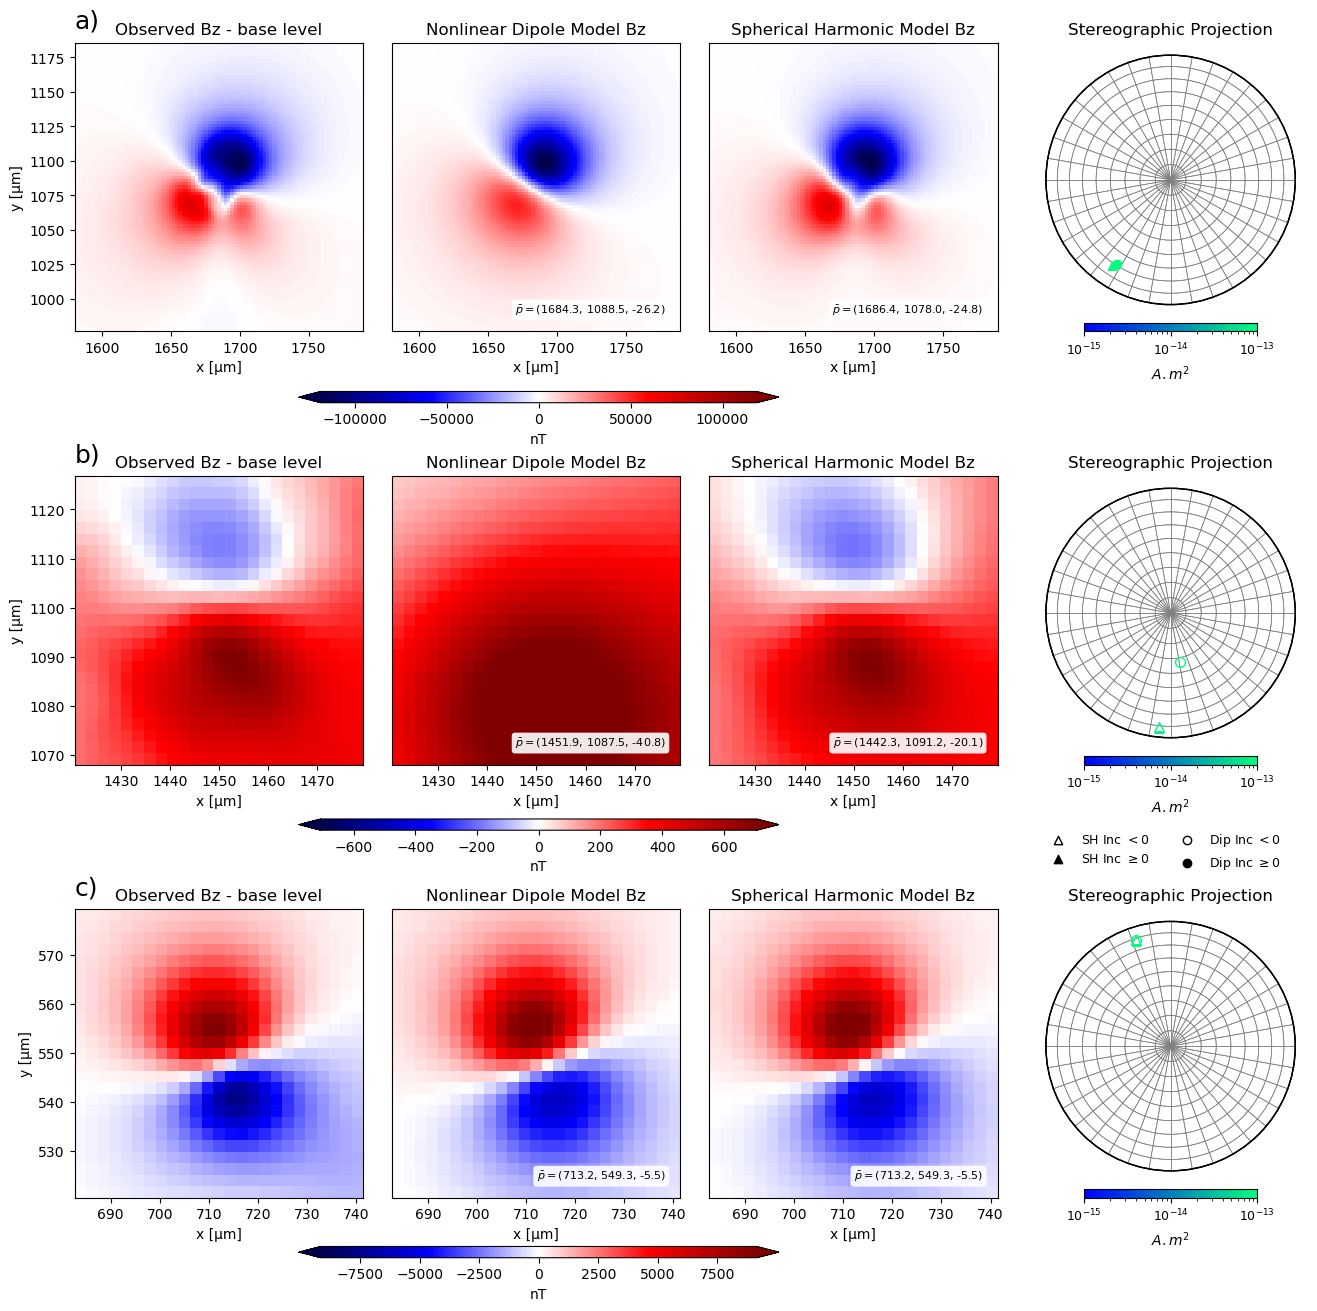

In [20]:
fig, axes = plt.subplots(len(zooms), 4, figsize=(16, 5 * len(zooms))) 

cmap = "rainbow"
cmap_norm = mcolors.LogNorm # Normalize
kwargs = dict(s=50, cmap=cmap, cmap_norm=cmap_norm)

ims = []
for i, window in enumerate(zooms):
    
     # find the anomaly within the zoom window
    x_dip = np.array(positions_dipole)[:,0]
    y_dip = np.array(positions_dipole)[:,1]
    z_dip = np.array(positions_dipole)[:,2]    
    
    x_SH = np.array(positions_SH)[:,0]
    y_SH = np.array(positions_SH)[:,1]
    z_SH = np.array(positions_SH)[:,2]

    xmin, xmax, ymin, ymax = window
    mask = (x_dip >= xmin) & (x_dip <= xmax) & (y_dip >= ymin) & (y_dip <= ymax)

    # get position and moment
    pos_dip = np.array(positions_dipole)[mask]
    pos_SH = np.array(positions_SH)[mask]

    m_dip = np.array(estimated_dipole_moments_dip)[mask]
    m_SH = np.array(estimated_dipole_moments_SH)[mask]

    # get base level
    base_level = (np.array(base_levels_SH)[mask])
    window_plot = data_up.sel(x=slice(*window[:2]), y=slice(*window[2:]))
    
    bz_corrected = window_plot["bz"] - base_level
    scale = vd.maxabs(bz_corrected)
    
    # Plot bz - base_level
    im = bz_corrected.plot.pcolormesh(
        ax=axes[i,0],
        cmap="seismic",
        vmin=-scale,
        vmax=scale,
        add_colorbar=False
    )

    ims.append(im)
    
    window_plot["dipole_nonlinear"].plot.pcolormesh(
    ax=axes[i,1],
    cmap="seismic",
    vmin=-scale,
    vmax=scale,
    add_colorbar=False)

    # print the dip position info
    if len(pos_dip) > 0:
            xd, yd, zd = pos_dip[0]
            texto_dip = r"$\bar{p}=$"+f"({xd:.1f}, {yd:.1f}, {zd:.1f})"
            axes[i,1].text(0.95, 0.05, texto_dip, 
                          transform=axes[i,1].transAxes,
                          fontsize=8, color='black',
                          ha='right', va='bottom', 
                          bbox=dict(facecolor='white', alpha=0.9, edgecolor='none', boxstyle='round,pad=0.3'))
        
    rmse_dip = np.sqrt(np.mean(bz_corrected.values-window_plot.dipole_nonlinear.values)**2)

    window_plot["spherical_harmonic"].plot.pcolormesh(
    ax=axes[i,2],
    cmap="seismic",
    vmin=-scale,
    vmax=scale,
    add_colorbar=False)

    rmse_SH= np.sqrt(np.mean(bz_corrected.values-window_plot.spherical_harmonic.values)**2)
    
    print(rmse_dip)
    print(rmse_SH)
    print()
    
    # print the SH position info
    if len(pos_SH) > 0:
            xs, ys, zs = pos_SH[0]
            texto_sh = r"$\bar{p}=$"+f"({xs:.1f}, {ys:.1f}, {zs:.1f})"
            axes[i,2].text(0.95, 0.05, texto_sh, 
                          transform=axes[i,2].transAxes, 
                          fontsize=8, color='black',
                          ha='right', va='bottom',
                          bbox=dict(facecolor='white', alpha=0.9, edgecolor='none', boxstyle='round,pad=0.3'))

    # ==========================================
    # Stereograms
    # ==========================================
    
    # if len(m_dip) > 0 and len(m_SH) > 0:
    
    # projection
    projection_dip = mg.StereographicProjection(m_dip)
    projection_SH = mg.StereographicProjection(m_SH)


    vmin = 1.0e-15#min(m_dip.min(), m_SH.min()) * 0.1
    vmax = 1.0e-13#(m_dip.max(), m_SH.max()) * 10

    kwargs = dict(s=50, cmap="winter", vmin=vmin, vmax=vmax, cmap_norm=cmap_norm)

    # dipole model
    tmp = projection_dip.plot(
        ax=axes[i, 3], draw_cross=False, add_radial_grid=True, 
        label=" Dip Inc", add_legend=False, add_ticks=False, **kwargs
    )
    
    # SH (Spherical Harmonic) model
    tmp = projection_SH.plot(
        ax=axes[i, 3], draw_cross=False, add_radial_grid=True, marker='^', 
        label="SH Inc", add_legend=False, add_ticks=False, **kwargs
    )
    
    # colorbar
    clb = fig.colorbar(tmp, ax=axes[i, 3], orientation="horizontal", 
                       fraction=0.03, pad=0.02)
    
    clb.set_label(label="$A.m^2$", fontsize=10)
    clb.ax.tick_params(labelsize=9)

# titles
for i in range(3):    
    axes[i,0].set_title('Observed Bz - base level')
    axes[i,1].set_title('Nonlinear Dipole Model Bz')
    axes[i,2].set_title('Spherical Harmonic Model Bz')
    axes[i,3].set_title('Stereographic Projection')

###
for i in range(3):
    for j in range(1,3):
        ax = axes[i,j]
        ax.set_ylabel("")                 # remove y-axis label
        ax.set_yticklabels([])            # remove tick labels
        ax.tick_params(axis='y', which='both', length=0)  # remove tick marks



##############################
cbar_ax = fig.add_axes([0.265, 0.64, 0.3, 0.0075])
cbar = fig.colorbar(
    ims[0],
    cax=cbar_ax,
    extend='both',
    orientation="horizontal"
)
cbar.set_label("nT")


cbar_ax = fig.add_axes([0.265, 0.355, 0.3, 0.0075])
cbar = fig.colorbar(
    ims[1],
    cax=cbar_ax,
    extend='both',
    orientation="horizontal"
)
cbar.set_label("nT")


cbar_ax = fig.add_axes([0.265, 0.07, 0.3, 0.0075])
cbar = fig.colorbar(
    ims[2],
    cax=cbar_ax,
    extend='both',
    orientation="horizontal"
)
cbar.set_label("nT")
##############################

# texts
axes[0,0].text(0, 1.05, 'a)', transform=axes[0,0].transAxes, fontsize=18)
axes[1,0].text(0, 1.05, 'b)', transform=axes[1,0].transAxes, fontsize=18)
axes[2,0].text(0, 1.05, 'c)', transform=axes[2,0].transAxes, fontsize=18)


#
axes[2,2].scatter([],[], color='k', marker='^', facecolor='w', label=r'SH Inc $< 0$')
axes[2,2].scatter([],[], color='k', marker='^', facecolor='k',  label=r'SH Inc $\geq 0$')
axes[2,2].scatter([],[], color='k', marker='o', facecolor='w', label=r'Dip Inc $<0$')
axes[2,2].scatter([],[], color='k', marker='o', facecolor='k',  label=r'Dip Inc $\geq 0$')

axes[2,2].legend(loc='center', bbox_to_anchor=(1.575, 1.2), ncol=2, frameon=False, fontsize=9)

plt.subplots_adjust(hspace=0.5, wspace=0.1)

plt.savefig(figure_dir / "zoom_real_data_results.png",
            dpi=300, bbox_inches="tight", transparent=True)

plt.show()

# Estimate sensor-sample distance

In [21]:
mask_pos_SH =  (r2_multipolar_estatimates > 0.95)
mask_pos_dip = (r2_dipolar_estatimates > 0.95)

# -10 -> 5µm from the assumed height in the inversion and 5µm from the upward continuation
# Usando .min() conforme solicitado
estimated_SH_sensor_sample_height = 10 - np.array(positions_SH)[:, 2][mask_pos_SH].max()
estimated_dip_sensor_sample_height = 10 - np.array(positions_dipole)[:, 2][mask_pos_dip].max()

print(f'Sensor height estimated with dipolar inversion: {estimated_dip_sensor_sample_height} µm')
print(f'Sensor height estimated with spherical harmonics inversion: {estimated_SH_sensor_sample_height} µm')

Sensor height estimated with dipolar inversion: 11.056943473641645 µm
Sensor height estimated with spherical harmonics inversion: 11.056943473641645 µm


# Run SH for variying maximum order to check for stability

In [22]:
DAMPING = 1.0e0

# Store all results for each spherical-harmonic degree
results_by_degree = {}

for MAX_DEGREE in range(1, 7):

    print(f"\n{'='*60}")
    print(f"Running spherical harmonics up to degree {MAX_DEGREE}")
    print(f"{'='*60}")

    # Reset data for each degree so that all inversions start
    # from exactly the same magnetic field.
    data_copy = data.copy(deep=True)
    data_up_copy = data_up.copy(deep=True)

    data_up = data_up.assign(
        spherical_harmonic=(
            ['y', 'x'],
            np.zeros_like(data_up.bz)
        )
    )

    estimated_dipole_moments_SH = []
    positions_SH = []
    base_levels_SH = []

    r2_dipolar_estatimates = np.zeros(len(windows))
    r2_multipolar_estatimates = np.zeros(len(windows))
    SH_was_used = np.zeros(len(windows), dtype=bool)

    total_data_table = vd.grid_to_table(data_up)

    coordinates = (
        total_data_table.x,
        total_data_table.y,
        total_data_table.z
    )

    # ---------------------------------------------------------------
    # Loop over all windows
    # ---------------------------------------------------------------

    for i, window in enumerate(
        rich.progress.track(
            np.array(windows),
            total=len(windows)
        )
    ):

        anomaly = data_up_copy.sel(
            x=slice(*window[:2]),
            y=slice(*window[2:])
        )

        position, base_level = mg.euler_deconvolution(
            anomaly.bz,
            anomaly.x_deriv,
            anomaly.y_deriv,
            anomaly.z_deriv,
        )

        data_minus_background = (
            anomaly.bz.values - base_level
        )

        anomaly = anomaly.assign(
            data_minus_background=(
                ['y', 'x'],
                data_minus_background
            )
        )

        anomaly.data_minus_background.attrs = {
            "long_name": "dipole-model",
            "units": "nT"
        }

        anomaly_table = vd.grid_to_table(anomaly)

        local_coordinates = (
            anomaly_table.x,
            anomaly_table.y,
            anomaly_table.z
        )

        #################################################################
        # Initial dipole inversion
        #################################################################

        moment, covariance, r2, SNR = mg.dipole_moment_inversion(
            anomaly.data_minus_background,
            position,
        )

        amplitude = np.linalg.norm(moment)

        #################################################################
        # Nonlinear dipole refinement
        #################################################################

        args_dip = (
            anomaly_table.bz.ravel(),
            (
                anomaly_table.x.values,
                anomaly_table.y.values,
                anomaly_table.z.values.ravel()
            ),
            amplitude,
            position[0],
            position[1],
            position[2]
        )

        minimization = sp.optimize.minimize(
            goal_function_dipole,
            (
                1,
                1,
                1,
                moment[0] / amplitude,
                moment[1] / amplitude,
                moment[2] / amplitude
            ),
            args=args_dip,
            method='Nelder-Mead',
            options=dict(maxiter=1000)
        )

        multi = False
        if minimization.success:

            moment = np.array([
                minimization['x'][3],
                minimization['x'][4],
                minimization['x'][5]
            ]) * amplitude

            position = np.array([
                minimization['x'][0] * position[0],
                minimization['x'][1] * position[1],
                minimization['x'][2] * position[2]
            ])

            xxx, yyy = np.meshgrid(
                anomaly.x.values,
                anomaly.y.values
            )

            zzz = anomaly.z.values.ravel()

            local_coordinates = [
                xxx.ravel(),
                yyy.ravel(),
                zzz
            ]

            pred = mg.dipole_bz(
                local_coordinates,
                position,
                moment
            )

            residuals = (
                data_minus_background.ravel()
                - pred.ravel()
            )

            residuals_sum_sq = np.sum(residuals**2)

            r2 = (
                1
                - residuals_sum_sq
                / np.linalg.norm(
                    data_minus_background.ravel()
                    - np.mean(data_minus_background.ravel())
                ) ** 2
            )

            # Save the dipole solution before attempting SH inversion
            # so that it can be restored if necessary.
            moment_dipole = moment.copy()
            position_dipole = position.copy()
            r2_dipole = r2

            r2_dipolar_estatimates[i] = r2

            #################################################################
            # Spherical-harmonic inversion
            #################################################################

            if r2 <= 0.95:

                multi = True
                r2_bubble = r2

                sph = mt.SphericalHarmonicsBz(
                    position,
                    damping=DAMPING,
                    min_degree=1,
                    max_degree=MAX_DEGREE
                ).fit(
                    local_coordinates,
                    anomaly_table.data_minus_background
                )

                sph.update_location(
                    local_coordinates,
                    anomaly_table.data_minus_background,
                    update_only_z=False
                )

                pred_sph = sph.predict(
                    local_coordinates,
                    min_degree=1,
                    max_degree=MAX_DEGREE
                )

                residuals = (
                    data_minus_background.ravel()
                    - pred_sph.ravel()
                )

                residuals_sum_sq = np.sum(residuals**2)

                r2 = (
                    1
                    - residuals_sum_sq
                    / np.linalg.norm(
                        data_minus_background.ravel()
                        - np.mean(data_minus_background.ravel())
                    ) ** 2
                )

                # Use the SH solution only if it improves the dipole fit
                if r2 >= r2_bubble:

                    moment = sph.magnetic_moment_
                    position = sph.location
                    pred = pred_sph

                    r2_multipolar_estatimates[i] = r2
                    SH_was_used[i] = True

        #################################################################
        # Avoid unrealistic deep or shallow solutions
        #################################################################

        if (position[2] < -300) or (position[2] > 5):

            moment = moment_dipole
            position = position_dipole
            r2 = r2_dipole
            multi = False

            r2_multipolar_estatimates[i] = r2
            SH_was_used[i] = False

        estimated_dipole_moments_SH.append(moment)
        positions_SH.append(position)
        base_levels_SH.append(base_level)

        #################################################################
        # Fill predicted data and discard anomalies
        #################################################################

        if r2 < 0.95:

            # Don't compute forward model for bad solutions
            discard = np.zeros_like(data_copy.bz.values)

        elif multi:

            discard = sph.predict(
                coordinates,
                min_degree=1,
                max_degree=MAX_DEGREE
            )

        else:

            discard = mg.dipole_bz(
                coordinates,
                position,
                moment
            )

        max_discard = np.max(np.abs(discard))
        max_field = np.max(np.abs(data_copy.bz.values))

        #################################################################
        # Reject unrealistic forward models
        #################################################################

        if max_discard > 2 * max_field:

            print(
                f"Rejecting subtraction: discard too large "
                f"({max_discard:.2e} > {2*max_field:.2e})"
            )

            discard = np.zeros_like(data_copy.bz.values)
            SH_was_used[i] = False

        shape = np.shape(data_up.bz)

        data_up.spherical_harmonic.values += (
            discard.reshape(shape)
        )

        data_copy.bz.values -= (
            discard.reshape(shape)
        )

        #################################################################
        # Recompute upward continuation and gradients
        #################################################################

        if np.isnan(data_copy.bz.values).any():

            print(
                f"NaN found after subtraction in {mat_path.name}, "
                f"replacing with zero"
            )

            data_copy["bz"] = data_copy.bz.fillna(0)

        data_up_copy = (
            hm.upward_continuation(
                data_copy.bz,
                height_difference
            )
            .assign_attrs(data_copy.bz.attrs)
            .to_dataset(name="bz")
            .assign_coords(
                x=data_copy.x,
                y=data_copy.y
            )
            .assign_coords(
                z=data_copy.z + height_difference
            )
        )

        data_up_copy = data_up_copy.assign(
            mg.data_gradients(data_up_copy.bz)
        )

    #####################################################################
    # Save results for this MAX_DEGREE
    #####################################################################
    
    results_by_degree[MAX_DEGREE] = {
        "moment": np.array(estimated_dipole_moments_SH),
        "position": np.array(positions_SH),
        "base_level": np.array(base_levels_SH),
        "r2_dipole": r2_dipolar_estatimates.copy(),
        "r2_multipolar": r2_multipolar_estatimates.copy(),
        "SH_was_used": SH_was_used.copy(),
    }

    print(
        f"Finished MAX_DEGREE={MAX_DEGREE}: "
        f"{np.sum(SH_was_used)} SH solutions used"
    )

Output()


Running spherical harmonics up to degree 1


Output()

Finished MAX_DEGREE=1: 26 SH solutions used

Running spherical harmonics up to degree 2


Output()

...

Output()

Finished MAX_DEGREE=4: 22 SH solutions used

Running spherical harmonics up to degree 5


Output()

Finished MAX_DEGREE=5: 24 SH solutions used

Running spherical harmonics up to degree 6


Finished MAX_DEGREE=6: 26 SH solutions used


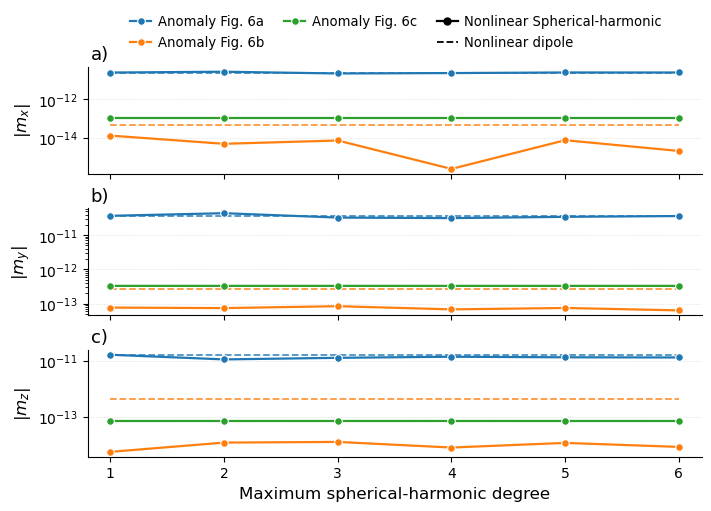

In [23]:
# ------------------------------------------------------------
# Settings
# ------------------------------------------------------------

degrees = np.arange(1, 7)

# One color for each selected anomaly
anomaly_colors = [
    "tab:blue",
    "tab:orange",
    "tab:green",
]

component_labels = [
    r"$|m_x|$",
    r"$|m_y|$",
    r"$|m_z|$",
]

panel_labels = ["a)", "b)", "c)"]

# Labels corresponding to the selected anomalies
anomaly_labels = [
    "Anomaly Fig. 5a",
    "Anomaly Fig. 5b",
    "Anomaly Fig. 5c",
]


# ------------------------------------------------------------
# Find one anomaly inside each selected zoom
# ------------------------------------------------------------

positions_dipole_array = np.asarray(positions_dipole)

window_indices = []

for window in zooms:

    xmin, xmax, ymin, ymax = window

    mask = (
        (positions_dipole_array[:, 0] >= xmin)
        & (positions_dipole_array[:, 0] <= xmax)
        & (positions_dipole_array[:, 1] >= ymin)
        & (positions_dipole_array[:, 1] <= ymax)
    )

    indices = np.where(mask)[0]

    if len(indices) == 0:
        raise ValueError(f"No anomaly found inside zoom: {window}")

    window_indices.append(indices[0])


# ------------------------------------------------------------
# Extract spherical-harmonic and dipole moments
# ------------------------------------------------------------

moments_selected = []
dipole_moments_selected = []

for index in window_indices:

    # Spherical-harmonic solutions for degrees 1-6
    moments = np.array([
        results_by_degree[degree]["moment"][index]
        for degree in degrees
    ])

    moments_selected.append(moments)

    # Nonlinear dipole solution
    dipole_moment = np.asarray(
        estimated_dipole_moments_dip[index]
    )

    dipole_moments_selected.append(dipole_moment)


fig, axes = plt.subplots(
    3,
    1,
    figsize=(7.0, 5.0),
    sharex=True,
    constrained_layout=True
)


for component, ax in enumerate(axes):

    for anomaly_index, (moments, dipole_moment) in enumerate(
        zip(moments_selected, dipole_moments_selected)
    ):

        color = anomaly_colors[anomaly_index]

        # ----------------------------------------------------
        # Spherical-harmonic solution
        # ----------------------------------------------------

        ax.plot(
            degrees,
            np.abs(moments[:, component]),
            color=color,
            marker="o",
            markersize=5.5,
            markeredgecolor="white",
            markeredgewidth=0.8,
            linewidth=1.6,
            linestyle="-",
            label=anomaly_labels[anomaly_index],
            zorder=3,
        )

        # ----------------------------------------------------
        # Dipole solution
        # ----------------------------------------------------

        ax.plot(
            degrees,
            np.full_like(
                degrees,
                np.abs(dipole_moment[component]),
                dtype=float
            ),
            color=color,
            linestyle="--",
            linewidth=1.3,
            alpha=0.8,
            zorder=2,
        )

    ax.set_yscale("log")

    # Panel label
    ax.text(
        0.005,
        1.2,
        panel_labels[component],
        transform=ax.transAxes,
        fontsize=13,
        # fontweight="bold",
        va="top",
    )

    ax.set_ylabel(
        component_labels[component],
        fontsize=12,
    )

    ax.grid(
        axis="y",
        which="major",
        linestyle=":",
        linewidth=0.7,
        alpha=0.4,
    )

    ax.yaxis.set_minor_locator(
        LogLocator(
            base=10,
            subs=np.arange(2, 10) * 0.1,
        )
    )

    ax.yaxis.set_minor_formatter(
        NullFormatter()
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.tick_params(
        direction="out",
        which="both",
        labelsize=10,
    )

axes[-1].set_xlabel(
    "Maximum spherical-harmonic degree",
    fontsize=12,
)

axes[-1].set_xticks(degrees)
axes[-1].set_xlim(0.8, 6.2)


legend_handles = [

    Line2D(
        [0], [0],
        color=anomaly_colors[0],
        marker="o",
        linestyle="-",
        markersize=5.5,
        markeredgecolor="white",
        markeredgewidth=0.8,
        linewidth=1.6,
        label="Anomaly Fig. 6a",
    ),

    Line2D(
        [0], [0],
        color=anomaly_colors[1],
        marker="o",
        linestyle="-",
        markersize=5.5,
        markeredgecolor="white",
        markeredgewidth=0.8,
        linewidth=1.6,
        label="Anomaly Fig. 6b",
    ),

    Line2D(
        [0], [0],
        color=anomaly_colors[2],
        marker="o",
        linestyle="-",
        markersize=5.5,
        markeredgecolor="white",
        markeredgewidth=0.8,
        linewidth=1.6,
        label="Anomaly Fig. 6c",
    ),

    Line2D(
        [], [],
        linestyle="none",
        label="",
    ),

    Line2D(
        [0], [0],
        color="black",
        linestyle="-",
        marker="o",
        markersize=5,
        linewidth=1.6,
        label="Nonlinear Spherical-harmonic",
    ),

    Line2D(
        [0], [0],
        color="black",
        linestyle="--",
        linewidth=1.3,
        label="Nonlinear dipole",
    ),
]

axes[0].legend(
    handles=legend_handles,
    loc="upper left",
    bbox_to_anchor=(0.05, 1.6),
    frameon=False,
    fontsize=9.5,
    ncol=3,
    handlelength=1.6,
    columnspacing=1.5,
    handletextpad=0.5,
)

fig.align_ylabels(axes)

plt.savefig(figure_dir / "supplementary_magnetic_components_zoom_results.png",
            dpi=300, bbox_inches="tight", transparent=True)

plt.show()

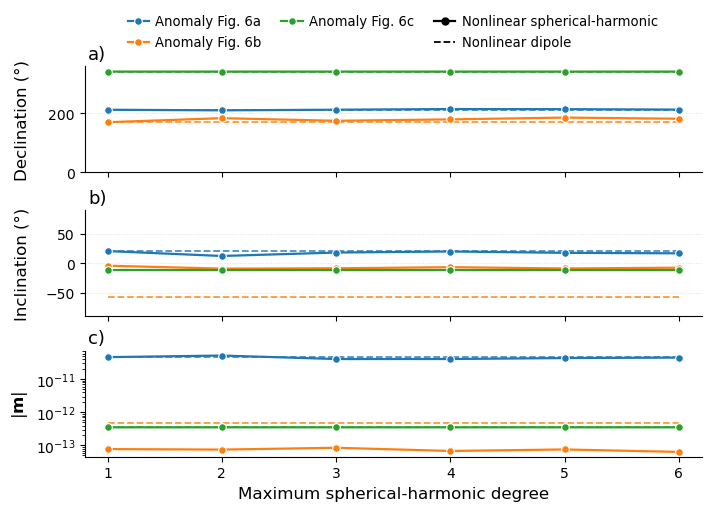

In [24]:
degrees = np.arange(1, 7)

anomaly_colors = [
    "tab:blue",
    "tab:orange",
    "tab:green",
]

panel_labels = ["a)", "b)", "c)"]

component_labels = [
    "Declination (°)",
    "Inclination (°)",
    r"$|\mathbf{m}|$",
]

anomaly_labels = [
    "Anomaly Fig. 5a",
    "Anomaly Fig. 5b",
    "Anomaly Fig. 5c",
]


# Find one anomaly inside each selected zoom

positions_dipole_array = np.asarray(positions_dipole)

window_indices = []

for window in zooms:
    xmin, xmax, ymin, ymax = window
    mask = (
        (positions_dipole_array[:, 0] >= xmin)
        & (positions_dipole_array[:, 0] <= xmax)
        & (positions_dipole_array[:, 1] >= ymin)
        & (positions_dipole_array[:, 1] <= ymax)
    )

    indices = np.where(mask)[0]

    if len(indices) == 0:
        raise ValueError(f"No anomaly found inside zoom: {window}")

    window_indices.append(indices[0])


# Extract moments

moments_selected = []
dipole_moments_selected = []

for index in window_indices:

    moments = np.array([
        results_by_degree[degree]["moment"][index]
        for degree in degrees
    ])

    moments_selected.append(moments)

    dipole_moment = np.asarray(
        estimated_dipole_moments_dip[index]
    )

    dipole_moments_selected.append(
        dipole_moment
    )


# Convert moments to Inc, Dec and intensity

directions_selected = []
dipole_directions_selected = []

for moments, dipole_moment in zip(
    moments_selected,
    dipole_moments_selected
):

    directions = np.array([
        mg.vector_to_angles(moment)
        for moment in moments
    ])

    # Convert declination from [-180, 180] to [0, 360)
    directions[:, 1] = directions[:, 1] % 360

    directions_selected.append(
        directions
    )

    dipole_direction = np.asarray(
        mg.vector_to_angles(dipole_moment)
    )

    dipole_direction[1] = dipole_direction[1] % 360

    dipole_directions_selected.append(
        dipole_direction
    )


# Figure

fig, axes = plt.subplots(
    3,
    1,
    figsize=(7.0, 5.0),
    sharex=True,
    constrained_layout=True
)


component_indices = [1, 0, 2]

for component, ax in enumerate(axes):

    data_index = component_indices[component]

    for anomaly_index, (
        directions,
        dipole_direction
    ) in enumerate(
        zip(
            directions_selected,
            dipole_directions_selected
        )
    ):

        color = anomaly_colors[anomaly_index]

        ax.plot(
            degrees,
            directions[:, data_index],
            color=color,
            marker="o",
            markersize=5.5,
            markeredgecolor="white",
            markeredgewidth=0.8,
            linewidth=1.6,
            linestyle="-",
            zorder=3,
        )

        ax.plot(
            degrees,
            np.full(
                len(degrees),
                dipole_direction[data_index],
                dtype=float
            ),
            color=color,
            linestyle="--",
            linewidth=1.3,
            alpha=0.8,
            zorder=2,
        )

    if component == 2:

        ax.set_yscale("log")

        ax.yaxis.set_minor_locator(
            LogLocator(
                base=10,
                subs=np.arange(2, 10) * 0.1,
            )
        )

        ax.yaxis.set_minor_formatter(
            NullFormatter()
        )

    else:

        ax.grid(
            axis="y",
            which="major",
            linestyle=":",
            linewidth=0.7,
            alpha=0.4,
        )

    ax.text(
        0.005,
        1.2,
        panel_labels[component],
        transform=ax.transAxes,
        fontsize=13,
        va="top",
    )

    ax.set_ylabel(
        component_labels[component],
        fontsize=12,
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.tick_params(
        direction="out",
        which="both",
        labelsize=10,
    )


axes[0].set_ylim(0, 360)
axes[1].set_ylim(-90, 90)


axes[-1].set_xlabel(
    "Maximum spherical-harmonic degree",
    fontsize=12,
)

axes[-1].set_xticks(degrees)
axes[-1].set_xlim(0.8, 6.2)


# Common legend

legend_handles = [

    Line2D(
        [0], [0],
        color=anomaly_colors[0],
        marker="o",
        linestyle="-",
        markersize=5.5,
        markeredgecolor="white",
        markeredgewidth=0.8,
        linewidth=1.6,
        label="Anomaly Fig. 6a",
    ),

    Line2D(
        [0], [0],
        color=anomaly_colors[1],
        marker="o",
        linestyle="-",
        markersize=5.5,
        markeredgecolor="white",
        markeredgewidth=0.8,
        linewidth=1.6,
        label="Anomaly Fig. 6b",
    ),

    Line2D(
        [0], [0],
        color=anomaly_colors[2],
        marker="o",
        linestyle="-",
        markersize=5.5,
        markeredgecolor="white",
        markeredgewidth=0.8,
        linewidth=1.6,
        label="Anomaly Fig. 6c",
    ),

    Line2D(
        [],
        [],
        linestyle="none",
        label="",
    ),

    Line2D(
        [0], [0],
        color="black",
        linestyle="-",
        marker="o",
        markersize=5,
        linewidth=1.6,
        label="Nonlinear spherical-harmonic",
    ),

    Line2D(
        [0], [0],
        color="black",
        linestyle="--",
        linewidth=1.3,
        label="Nonlinear dipole",
    ),
]

axes[0].legend(
    handles=legend_handles,
    loc="upper left",
    bbox_to_anchor=(0.05, 1.6),
    frameon=False,
    fontsize=9.5,
    ncol=3,
    handlelength=1.6,
    columnspacing=1.5,
    handletextpad=0.5,
)


fig.align_ylabels(axes)
plt.savefig(figure_dir / "supplementary_misfits_zoom_results.png",
            dpi=300, bbox_inches="tight", transparent=True)

plt.show()